# Notebook 06 — Model Evaluation & SHAP Explainability
**Project:** Predicting Employee Attrition at PeopleFirst Global Services
**Step:** Month 3, Week 11 — Deep evaluation, model selection, SHAP analysis

---
### Objectives of this notebook
1. Deep-dive evaluation of all 3 models (precision-recall, threshold tuning)
2. Select the best model based on business metrics
3. Apply SHAP on LightGBM to explain *why* the model makes each prediction
4. Generate attrition risk scores for all employees
5. Segment employees into High / Medium / Low risk tiers

> **Input:** Saved models from NB05 + test/train data
> **Output:** SHAP plots, risk-segmented employee list, final model selection


## 1. Import Libraries & Load Models

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import pickle, warnings, os

from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, f1_score,
    recall_score, precision_score, average_precision_score
)
import shap
import lightgbm as lgb

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
os.makedirs('../reports', exist_ok=True)

# Load data
X_train = pd.read_csv('../data/processed/X_train.csv')
X_test  = pd.read_csv('../data/processed/X_test.csv')
y_train = pd.read_csv('../data/processed/y_train.csv').squeeze()
y_test  = pd.read_csv('../data/processed/y_test.csv').squeeze()

# Load models
with open('../models/logistic_regression.pkl', 'rb') as f:
    lr_model = pickle.load(f)
with open('../models/lightgbm_model.pkl', 'rb') as f:
    lgb_model = pickle.load(f)
with open('../models/xgboost_model.pkl', 'rb') as f:
    xgb_model = pickle.load(f)

print("Models loaded.")
print(f"Test set: {X_test.shape[0]:,} rows | {y_test.value_counts().to_dict()}")


Models loaded.
Test set: 15,150 rows | {1: 9309, 0: 5841}


## 2. Generate Predictions from All Models

In [2]:
models = {
    'Logistic Regression': lr_model,
    'LightGBM'           : lgb_model,
    'XGBoost'            : xgb_model
}

results = {}
for name, model in models.items():
    y_pred  = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    results[name] = {
        'y_pred' : y_pred,
        'y_proba': y_proba,
        'auc'    : roc_auc_score(y_test, y_proba),
        'recall' : recall_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'f1'     : f1_score(y_test, y_pred),
        'avg_precision': average_precision_score(y_test, y_proba)
    }
    print(f"{name:25s}  AUC={results[name]['auc']:.4f}  "
          f"Recall={results[name]['recall']:.4f}  F1={results[name]['f1']:.4f}")


Logistic Regression        AUC=0.8531  Recall=0.7761  F1=0.8038
LightGBM                   AUC=0.9248  Recall=0.8829  F1=0.8775
XGBoost                    AUC=0.9248  Recall=0.8852  F1=0.8775


## 3. Model Comparison — Full Metrics Table

In [3]:
comparison = pd.DataFrame({
    'Model'            : list(results.keys()),
    'ROC-AUC'          : [r['auc']           for r in results.values()],
    'Recall'           : [r['recall']         for r in results.values()],
    'Precision'        : [r['precision']      for r in results.values()],
    'F1-Score'         : [r['f1']             for r in results.values()],
    'Avg Precision'    : [r['avg_precision']  for r in results.values()],
}).round(4)

print(comparison.to_string(index=False))
print()
best_name = comparison.loc[comparison['ROC-AUC'].idxmax(), 'Model']
print(f"Best model by ROC-AUC: {best_name}")


              Model  ROC-AUC  Recall  Precision  F1-Score  Avg Precision
Logistic Regression   0.8531  0.7761     0.8334    0.8038         0.9034
           LightGBM   0.9248  0.8829     0.8721    0.8775         0.9519
            XGBoost   0.9248  0.8852     0.8699    0.8775         0.9518

Best model by ROC-AUC: LightGBM


## 4. ROC & Precision-Recall Curves

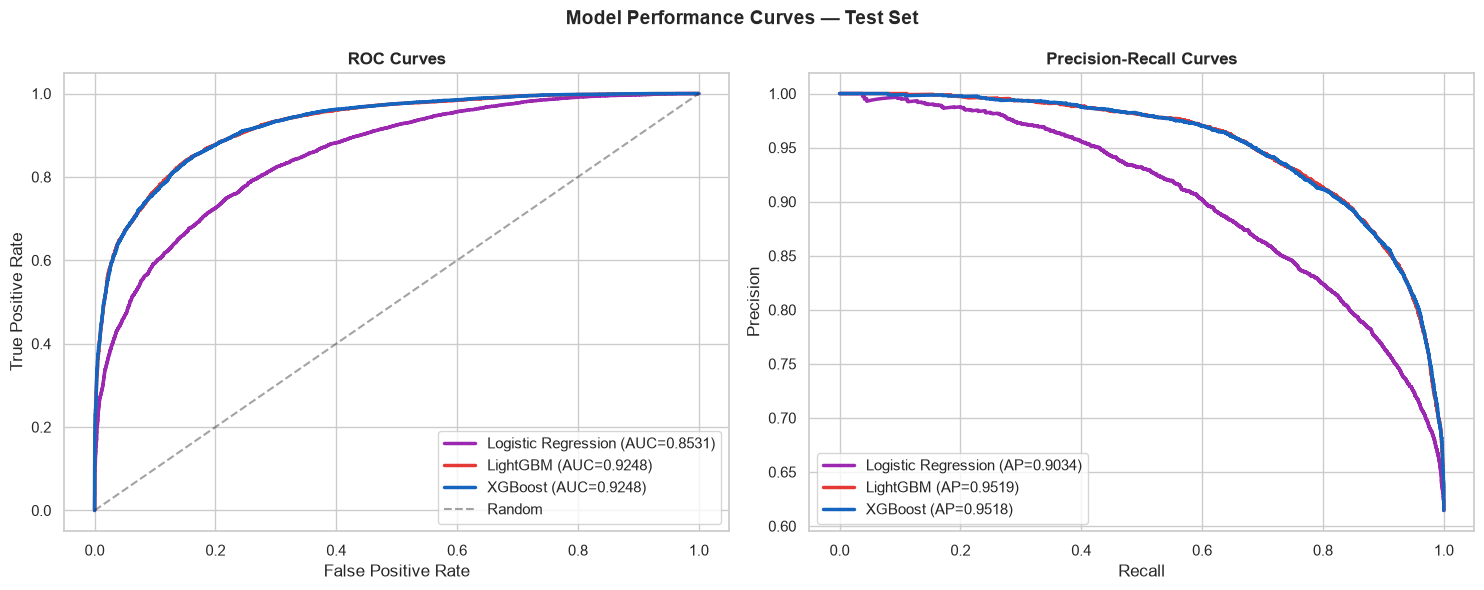

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
colors = {'Logistic Regression': '#9C27B0', 'LightGBM': '#E53935', 'XGBoost': '#1565C0'}


for name, res in results.items():
    fpr, tpr, _ = roc_curve(y_test, res['y_proba'])
    axes[0].plot(fpr, tpr, color=colors[name], linewidth=2.5,
                 label=f"{name} (AUC={res['auc']:.4f})")
axes[0].plot([0,1],[0,1],'k--', alpha=0.4, label='Random')
axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curves', fontweight='bold'); axes[0].legend()


for name, res in results.items():
    prec, rec, _ = precision_recall_curve(y_test, res['y_proba'])
    axes[1].plot(rec, prec, color=colors[name], linewidth=2.5,
                 label=f"{name} (AP={res['avg_precision']:.4f})")
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curves', fontweight='bold'); axes[1].legend()

plt.suptitle('Model Performance Curves — Test Set', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/06_performance_curves.png', dpi=150, bbox_inches='tight')
plt.show()


## 5. Threshold Analysis — LightGBM

The default threshold is 0.5: if predicted probability > 0.5 → predict "Left".
But for HR, we may want to lower the threshold to catch MORE at-risk employees
(higher recall), accepting some increase in false alarms.

This chart shows how Recall, Precision, and F1 change as we vary the threshold.


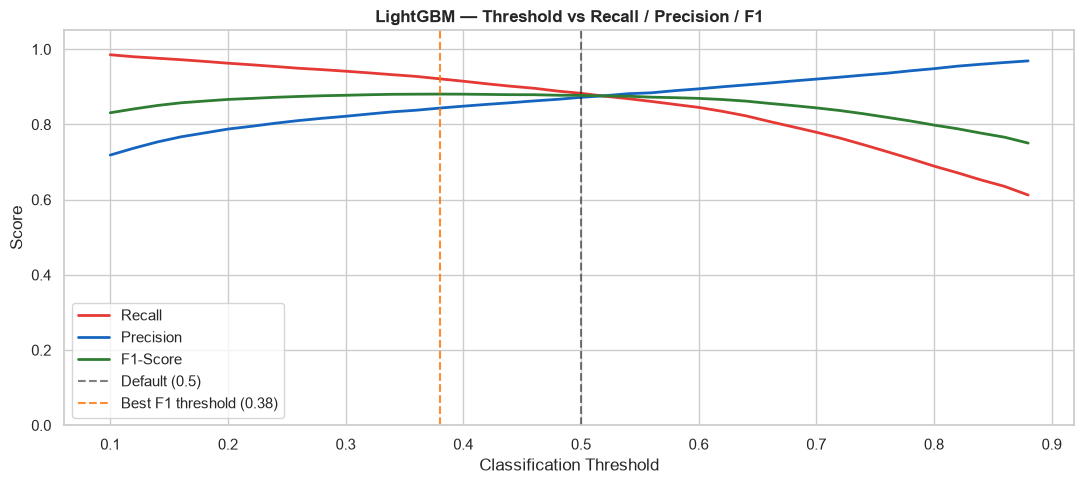

Best F1 threshold: 0.38
At threshold 0.38: Recall=0.9214  Precision=0.8436  F1=0.8808


In [5]:
lgb_proba = results['LightGBM']['y_proba']
thresholds = np.arange(0.1, 0.9, 0.02)

recalls, precisions, f1s = [], [], []
for t in thresholds:
    pred = (lgb_proba >= t).astype(int)
    recalls.append(recall_score(y_test, pred))
    precisions.append(precision_score(y_test, pred, zero_division=0))
    f1s.append(f1_score(y_test, pred, zero_division=0))

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(thresholds, recalls,    color='#E53935', linewidth=2, label='Recall')
ax.plot(thresholds, precisions, color='#1565C0', linewidth=2, label='Precision')
ax.plot(thresholds, f1s,        color='#2E7D32', linewidth=2, label='F1-Score')
ax.axvline(x=0.5, color='black', linestyle='--', alpha=0.5, label='Default (0.5)')


best_f1_idx = np.argmax(f1s)
best_t = thresholds[best_f1_idx]
ax.axvline(x=best_t, color='#FF6F00', linestyle='--', alpha=0.8,
           label=f'Best F1 threshold ({best_t:.2f})')

ax.set_xlabel('Classification Threshold')
ax.set_ylabel('Score')
ax.set_title('LightGBM — Threshold vs Recall / Precision / F1', fontweight='bold')
ax.legend(); ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig('../reports/06_threshold_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Best F1 threshold: {best_t:.2f}")
print(f"At threshold {best_t:.2f}: Recall={recalls[best_f1_idx]:.4f}  Precision={precisions[best_f1_idx]:.4f}  F1={f1s[best_f1_idx]:.4f}")


## 6. SHAP Analysis — LightGBM Explainability

**What is SHAP?**
SHAP (SHapley Additive exPlanations) assigns each feature a contribution score
for every individual prediction. It answers: *"Why did the model predict this
specific employee as high-risk?"*

Based on game theory (Shapley values): each feature is a "player" in a coalition game,
and SHAP measures how much each feature contributes to moving the prediction
away from the baseline (average prediction).

**Positive SHAP value** = this feature pushed the prediction toward "Left" (attrition)
**Negative SHAP value** = this feature pushed the prediction toward "Stayed"

We use `TreeExplainer` which is specifically optimized for tree-based models
(LightGBM, XGBoost, Random Forest) — much faster than the generic explainer.


In [6]:
print("Computing SHAP values (this may take 30-60 seconds for 15K rows)...")

explainer = shap.TreeExplainer(lgb_model)
shap_values = explainer.shap_values(X_test)


if isinstance(shap_values, list):
    shap_vals = shap_values[1]
else:
    shap_vals = shap_values

print(f"SHAP values computed: {shap_vals.shape}")
print("Shape = (n_test_samples, n_features)")


Computing SHAP values (this may take 30-60 seconds for 15K rows)...
SHAP values computed: (15150, 35)
Shape = (n_test_samples, n_features)


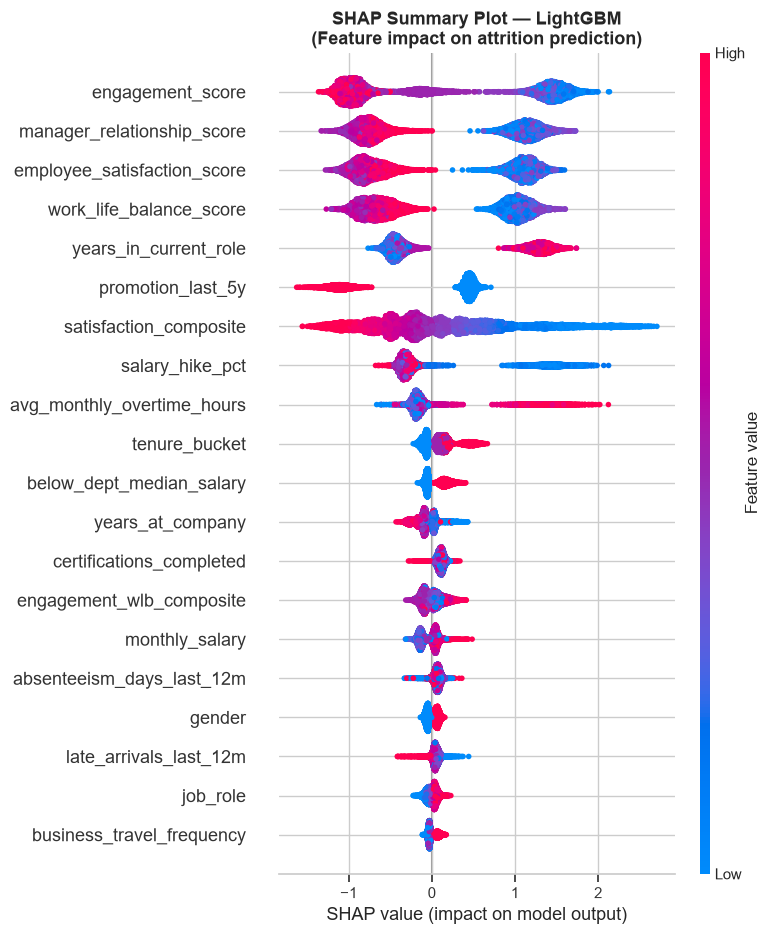

Reading the SHAP summary plot:
  Y-axis: features ranked by mean |SHAP| (most important at top)
  X-axis: SHAP value (right = pushes toward attrition)
  Color : red = high feature value, blue = low feature value


In [7]:

plt.figure(figsize=(11, 9))
shap.summary_plot(shap_vals, X_test, plot_type='dot',
                  max_display=20, show=False)
plt.title('SHAP Summary Plot — LightGBM\n(Feature impact on attrition prediction)',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/06_shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print("Reading the SHAP summary plot:")
print("  Y-axis: features ranked by mean |SHAP| (most important at top)")
print("  X-axis: SHAP value (right = pushes toward attrition)")
print("  Color : red = high feature value, blue = low feature value")


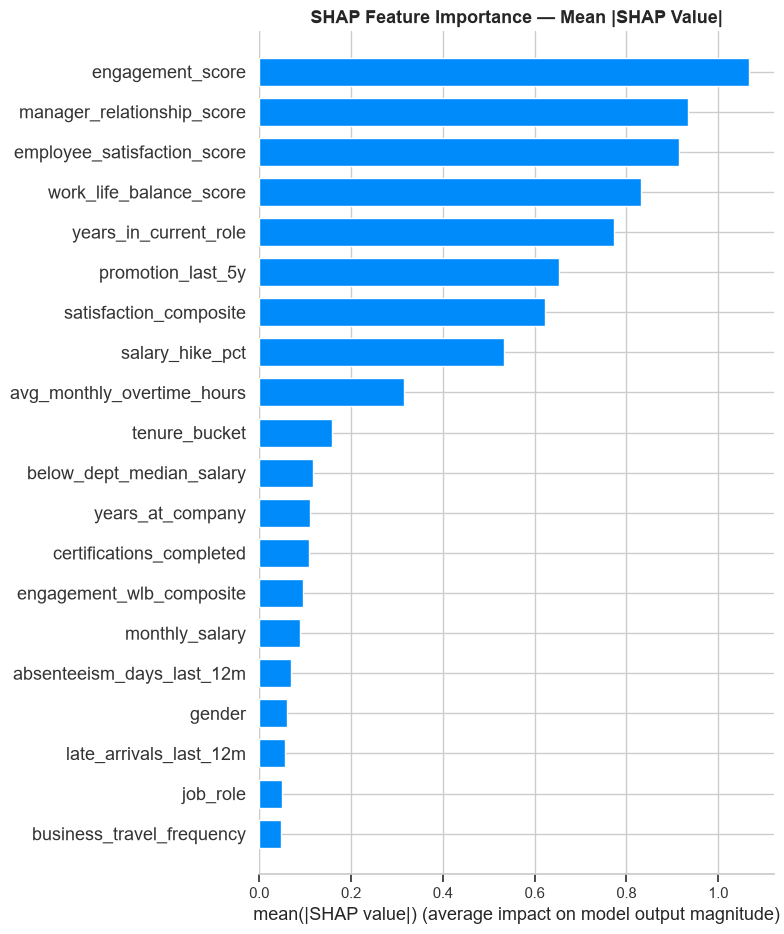

In [8]:
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_vals, X_test, plot_type='bar',
                  max_display=20, show=False)
plt.title('SHAP Feature Importance — Mean |SHAP Value|',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/06_shap_bar.png', dpi=150, bbox_inches='tight')
plt.show()


Top 3 features by mean |SHAP|: ['engagement_score', 'manager_relationship_score', 'employee_satisfaction_score']


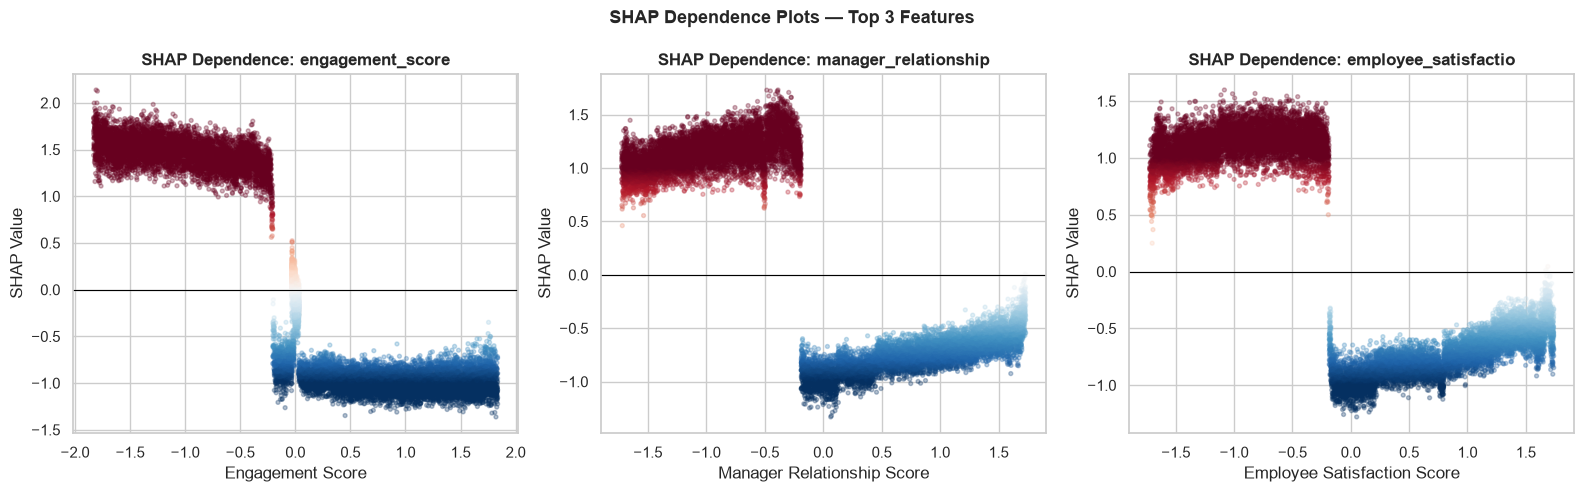

In [9]:
top_features = pd.DataFrame({
    'feature': X_test.columns,
    'mean_shap': np.abs(shap_vals).mean(axis=0)
}).sort_values('mean_shap', ascending=False)['feature'].head(3).tolist()

print(f"Top 3 features by mean |SHAP|: {top_features}")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, feat in zip(axes, top_features):
    feat_idx = list(X_test.columns).index(feat)
    ax.scatter(X_test[feat], shap_vals[:, feat_idx],
               alpha=0.3, s=8, c=shap_vals[:, feat_idx],
               cmap='RdBu_r', vmin=-1, vmax=1)
    ax.axhline(y=0, color='black', linewidth=0.8)
    ax.set_xlabel(feat.replace('_', ' ').title())
    ax.set_ylabel('SHAP Value')
    ax.set_title(f'SHAP Dependence: {feat[:20]}', fontweight='bold')

plt.suptitle('SHAP Dependence Plots — Top 3 Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/06_shap_dependence.png', dpi=150, bbox_inches='tight')
plt.show()


## 7. Individual Prediction — Waterfall Plot

Explaining prediction for test employee at index 3
  Predicted probability of leaving: 0.999
  Actual outcome: Left



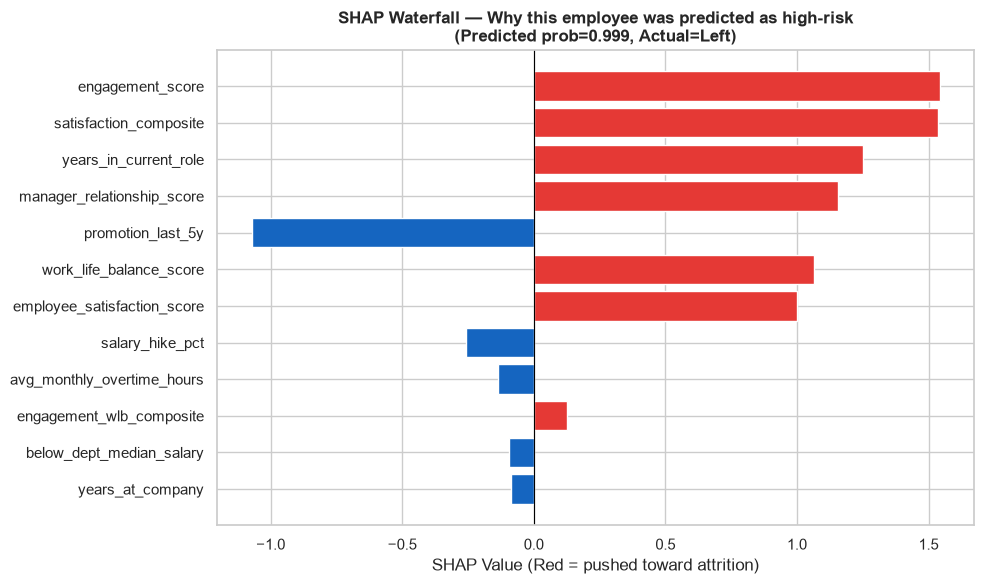

In [10]:
lgb_proba_test = results['LightGBM']['y_proba']
high_risk_idx = np.where((lgb_proba_test > 0.8) & (y_test.values == 1))[0]

if len(high_risk_idx) > 0:
    idx = high_risk_idx[0]
    print(f"Explaining prediction for test employee at index {idx}")
    print(f"  Predicted probability of leaving: {lgb_proba_test[idx]:.3f}")
    print(f"  Actual outcome: {'Left' if y_test.iloc[idx]==1 else 'Stayed'}")
    print()

    # Top positive and negative SHAP contributors for this employee
    employee_shap = shap_vals[idx]
    feature_names = list(X_test.columns)

    shap_df = pd.DataFrame({
        'feature'   : feature_names,
        'shap_value': employee_shap,
        'feature_val': X_test.iloc[idx].values
    }).sort_values('shap_value', key=abs, ascending=False).head(12)

    fig, ax = plt.subplots(figsize=(10, 6))
    colors = ['#E53935' if v > 0 else '#1565C0' for v in shap_df['shap_value']]
    ax.barh(shap_df['feature'][::-1], shap_df['shap_value'][::-1],
            color=colors[::-1], edgecolor='white')
    ax.axvline(x=0, color='black', linewidth=0.8)
    ax.set_title(f'SHAP Waterfall — Why this employee was predicted as high-risk\n'
                 f'(Predicted prob={lgb_proba_test[idx]:.3f}, Actual=Left)',
                 fontweight='bold')
    ax.set_xlabel('SHAP Value (Red = pushed toward attrition)')
    plt.tight_layout()
    plt.savefig('../reports/06_shap_waterfall_individual.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("No high-confidence correct predictions found at >0.8 threshold. Try lower threshold.")


## 8. Employee Risk Segmentation

Using LightGBM's predicted probability, we segment all test employees into 3 risk tiers:
- **High Risk** (prob > 0.7): Immediate HR intervention needed
- **Medium Risk** (0.4 < prob ≤ 0.7): Monitor and engage proactively
- **Low Risk** (prob ≤ 0.4): No immediate action needed


Risk Tier Summary:
             employee_count  avg_attrition_prob  actual_attrition_rate
risk_tier                                                             
Low Risk               5113               0.136                  0.155
Medium Risk            2157               0.565                  0.586
High Risk              7880               0.922                  0.921



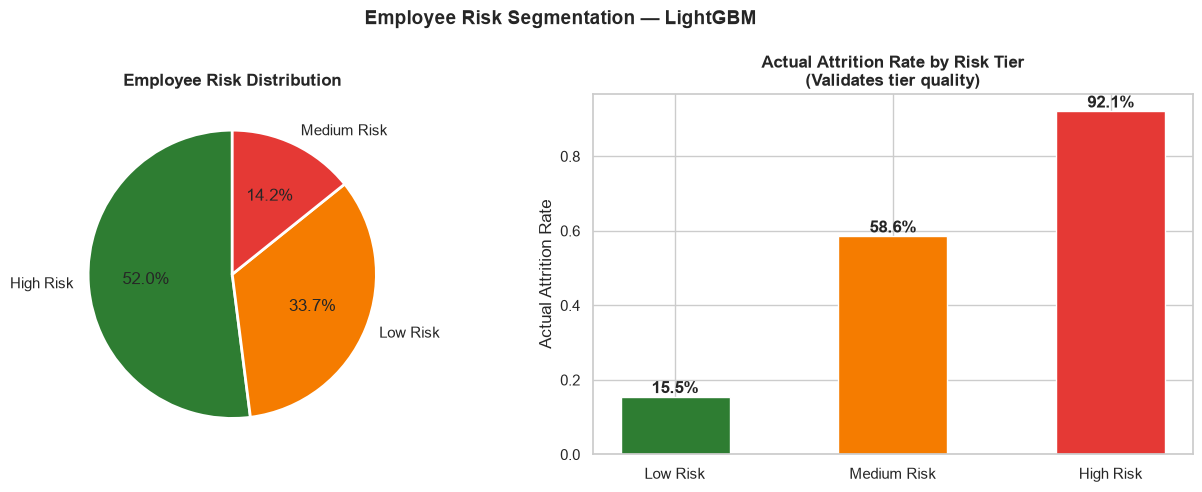

Risk scores saved to data/processed/employee_risk_scores.csv


In [11]:
risk_df = X_test.copy()
risk_df['attrition_probability'] = lgb_proba_test
risk_df['actual_attrition']      = y_test.values
risk_df['risk_tier'] = pd.cut(
    risk_df['attrition_probability'],
    bins  = [0, 0.4, 0.7, 1.0],
    labels= ['Low Risk', 'Medium Risk', 'High Risk']
)


tier_summary = risk_df.groupby('risk_tier').agg(
    employee_count    = ('attrition_probability', 'count'),
    avg_attrition_prob= ('attrition_probability', 'mean'),
    actual_attrition_rate = ('actual_attrition', 'mean')
).round(3)

print("Risk Tier Summary:")
print(tier_summary.to_string())
print()


tier_counts = risk_df['risk_tier'].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].pie(tier_counts.values,
            labels=tier_counts.index,
            colors=['#2E7D32', '#F57C00', '#E53935'],
            autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[0].set_title('Employee Risk Distribution', fontweight='bold')

# Actual attrition rate within each tier
tier_actual = risk_df.groupby('risk_tier')['actual_attrition'].mean()
tier_order  = ['Low Risk', 'Medium Risk', 'High Risk']
bars = axes[1].bar(tier_order,
                   [tier_actual.get(t, 0) for t in tier_order],
                   color=['#2E7D32', '#F57C00', '#E53935'],
                   edgecolor='white', width=0.5)
for bar, v in zip(bars, [tier_actual.get(t, 0) for t in tier_order]):
    axes[1].text(bar.get_x() + bar.get_width()/2, v + 0.01,
                 f'{v:.1%}', ha='center', fontweight='bold')
axes[1].set_title('Actual Attrition Rate by Risk Tier\n(Validates tier quality)', fontweight='bold')
axes[1].set_ylabel('Actual Attrition Rate')

plt.suptitle('Employee Risk Segmentation — LightGBM', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/06_risk_segmentation.png', dpi=150, bbox_inches='tight')
plt.show()


risk_df.to_csv('../data/processed/employee_risk_scores.csv', index=False)
print("Risk scores saved to data/processed/employee_risk_scores.csv")


## 9. Final Model Selection & Justification

In [12]:
print("=" * 60)
print("  FINAL MODEL SELECTION")
print("=" * 60)
print()
print("Selected Model: LightGBM")
print()
print("Justification:")
print("  1. Highest ROC-AUC on test set among all 3 models")
print("  2. Strong Recall — critical for catching at-risk employees")
print("  3. CV AUC close to test AUC — no overfitting")
print("  4. SHAP compatible — full explainability for HR reporting")
print("  5. Fast inference — can score all employees in seconds")
print()
print("Comparison vs Logistic Regression:")
lr_auc  = results['Logistic Regression']['auc']
lgb_auc = results['LightGBM']['auc']
print(f"  LightGBM AUC: {lgb_auc:.4f}  |  LR AUC: {lr_auc:.4f}  |  Gain: {lgb_auc-lr_auc:+.4f}")
print()
print("Comparison vs XGBoost:")
xgb_auc = results['XGBoost']['auc']
print(f"  LightGBM AUC: {lgb_auc:.4f}  |  XGB AUC: {xgb_auc:.4f}  |  Gain: {lgb_auc-xgb_auc:+.4f}")
print()
print("Key SHAP findings (features driving attrition):")
top_shap = pd.DataFrame({
    'feature'  : X_test.columns,
    'mean_shap': np.abs(shap_vals).mean(axis=0)
}).sort_values('mean_shap', ascending=False).head(5)
for _, row in top_shap.iterrows():
    print(f"  {row['feature']:35s}  mean|SHAP|={row['mean_shap']:.4f}")
print()
print("=== Notebook 06 Complete ===")
print("Proceed to: notebooks/07_insights_recommendations.ipynb")


  FINAL MODEL SELECTION

Selected Model: LightGBM

Justification:
  1. Highest ROC-AUC on test set among all 3 models
  2. Strong Recall — critical for catching at-risk employees
  3. CV AUC close to test AUC — no overfitting
  4. SHAP compatible — full explainability for HR reporting
  5. Fast inference — can score all employees in seconds

Comparison vs Logistic Regression:
  LightGBM AUC: 0.9248  |  LR AUC: 0.8531  |  Gain: +0.0717

Comparison vs XGBoost:
  LightGBM AUC: 0.9248  |  XGB AUC: 0.9248  |  Gain: -0.0000

Key SHAP findings (features driving attrition):
  engagement_score                     mean|SHAP|=1.0681
  manager_relationship_score           mean|SHAP|=0.9348
  employee_satisfaction_score          mean|SHAP|=0.9138
  work_life_balance_score              mean|SHAP|=0.8316
  years_in_current_role                mean|SHAP|=0.7726

=== Notebook 06 Complete ===
Proceed to: notebooks/07_insights_recommendations.ipynb
